# Expert Evaluation Questionnaire — Detailed Results Analysis

Analysis of two-expert Likert ratings (Q1–Q20) across nine de-identified HMS screening cases for the agentic XAI–RAG decision-support framework.

**Data source:** `questionnaire_responses.py` → `expert_evaluation_complete.zip` / `expert_evaluation_data/`

**Scale:** 1 (strongly disagree) – 5 (strongly agree)

**Sections:**
1. Data loading & integrity checks  
2. Descriptive statistics (item / dimension / case)  
3. Inter-expert agreement  
4. Dimension profiles & target mean comparison  
5. Case-level patterns & weak items  
6. Visualizations  
7. Manuscript-ready summary

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

DATA = Path("expert_evaluation_data")
if not DATA.exists():
    DATA = Path("paper_outputs/expert_evaluation_data")

Q_COLS = [f"Q{i}" for i in range(1, 21)]

DIMS = {
    "XAI Interpretability": ["Q1", "Q2", "Q3", "Q4"],
    "Evidence Grounding": ["Q5", "Q6", "Q7", "Q8"],
    "Report Quality": ["Q9", "Q10", "Q11", "Q12"],
    "Safety & Responsible Communication": ["Q13", "Q14", "Q15", "Q16"],
    "Framework Usefulness": ["Q17", "Q18", "Q19", "Q20"],
}

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

print("Data dir:", DATA.resolve())

Data dir: C:\Users\MossabBatal\Desktop\psychology_mas\paper_outputs\expert_evaluation_data


## 1. Load data & integrity checks

In [2]:
questions = pd.read_csv(DATA / "questions_list.csv")
categories = pd.read_csv(DATA / "question_categories.csv")
e1 = pd.read_csv(DATA / "expert_1_responses.csv").set_index("Case_ID")
e2 = pd.read_csv(DATA / "expert_2_responses.csv").set_index("Case_ID")
avg_file = pd.read_csv(DATA / "experts_average.csv").set_index("Case_ID")

# Long format for mixed analyses
def to_long(df: pd.DataFrame, expert: str) -> pd.DataFrame:
    out = df[Q_COLS].reset_index().melt(id_vars="Case_ID", var_name="Question", value_name="Score")
    out["Expert"] = expert
    return out

long = pd.concat([to_long(e1, "E1"), to_long(e2, "E2")], ignore_index=True)
q_to_dim = {q: dim for dim, qs in DIMS.items() for q in qs}
long["Dimension"] = long["Question"].map(q_to_dim)

avg_computed = (e1[Q_COLS] + e2[Q_COLS]) / 2.0

print("Questions:", len(questions))
print("Cases:", list(e1.index))
print("Score range E1:", e1[Q_COLS].min().min(), "–", e1[Q_COLS].max().max())
print("Score range E2:", e2[Q_COLS].min().min(), "–", e2[Q_COLS].max().max())
print("Missing E1/E2:", int(e1[Q_COLS].isna().sum().sum()), int(e2[Q_COLS].isna().sum().sum()))

# Verify provided average matches recomputed mean
max_diff = (avg_file[Q_COLS] - avg_computed[Q_COLS]).abs().max().max()
print(f"Max |provided avg − recomputed| = {max_diff:.6f}")
assert max_diff < 1e-9, "experts_average.csv does not match (E1+E2)/2"
print("Integrity check passed.")

display(questions.head())
display(categories)

Questions: 20
Cases: ['Case_1', 'Case_2', 'Case_3', 'Case_4', 'Case_5', 'Case_6', 'Case_7', 'Case_8', 'Case_9']
Score range E1: 2 – 5
Score range E2: 2 – 5
Missing E1/E2: 0 0
Max |provided avg − recomputed| = 0.000000
Integrity check passed.


,Question_ID,Question_Text
0,Q1,The XAI explanation clearly identifies the mai...
1,Q2,The contribution of each feature is presented ...
2,Q3,The explanation appropriately distinguishes pr...
3,Q4,The XAI information improves understanding of ...
4,Q5,The retrieved evidence passages are relevant t...


,Evaluation_Dimension,Question_Range,Target_Mean
0,XAI Interpretability,Q1-Q4,4.25
1,Evidence Grounding,Q5-Q8,3.85
2,Report Quality,Q9-Q12,4.20
3,Safety & Responsible Communication,Q13-Q16,4.45
4,Framework Usefulness,Q17-Q20,4.30


## 2. Descriptive statistics

### 2.1 Per-item descriptives (pooled across experts × cases)

In [3]:
item_stats = (
    long.groupby("Question")["Score"]
    .agg(n="count", mean="mean", sd="std", median="median", min="min", max="max")
    .reindex(Q_COLS)
)
item_stats["Dimension"] = [q_to_dim[q] for q in item_stats.index]
item_stats["mean_sd"] = item_stats.apply(lambda r: f"{r['mean']:.2f} ± {r['sd']:.2f}", axis=1)

item_display = item_stats[["Dimension", "n", "mean", "sd", "median", "min", "max", "mean_sd"]].copy()
item_display = item_display.merge(
    questions.rename(columns={"Question_ID": "Question", "Question_Text": "Text"}),
    left_index=True,
    right_on="Question",
    how="left",
).set_index("Question")

print("Overall pooled mean ± SD:", f"{long['Score'].mean():.2f} ± {long['Score'].std():.2f}")
print("Lowest-rated items:")
display(item_display.sort_values("mean").head(5)[["Dimension", "mean_sd", "Text"]])
print("Highest-rated items:")
display(item_display.sort_values("mean", ascending=False).head(5)[["Dimension", "mean_sd", "Text"]])
display(item_display[["Dimension", "mean", "sd", "median", "min", "max"]])

Overall pooled mean ± SD: 4.18 ± 0.78
Lowest-rated items:


,Dimension,mean_sd,Text
Question,,,
Q7,Evidence Grounding,3.17 ± 0.92,The retrieved evidence is sufficient to suppor...
Q3,XAI Interpretability,3.44 ± 0.86,The explanation appropriately distinguishes pr...
Q8,Evidence Grounding,3.50 ± 0.92,The relationship between the generated report ...
Q15,Safety & Responsible Communication,3.83 ± 1.04,The report avoids unsupported causal interpret...
Q10,Report Quality,4.00 ± 0.69,The generated report integrates the prediction...


Highest-rated items:


,Dimension,mean_sd,Text
Question,,,
Q16,Safety & Responsible Communication,4.67 ± 0.49,The report appropriately indicates the need fo...
Q13,Safety & Responsible Communication,4.61 ± 0.70,The report clearly distinguishes screening-thr...
Q4,XAI Interpretability,4.56 ± 0.51,The XAI information improves understanding of ...
Q1,XAI Interpretability,4.50 ± 0.51,The XAI explanation clearly identifies the mai...
Q20,Framework Usefulness,4.50 ± 0.51,"Overall, the proposed framework represents a u..."


,Dimension,mean,sd,median,min,max
Question,,,,,,
Q1,XAI Interpretability,4.500000,0.514496,4.5,4,5
Q2,XAI Interpretability,4.444444,0.615699,4.5,3,5
Q3,XAI Interpretability,3.444444,0.855585,4.0,2,5
Q4,XAI Interpretability,4.555556,0.511310,5.0,4,5
Q5,Evidence Grounding,4.222222,0.646762,4.0,3,5
Q6,Evidence Grounding,4.166667,0.707107,4.0,3,5
Q7,Evidence Grounding,3.166667,0.923548,3.0,2,5
Q8,Evidence Grounding,3.500000,0.923548,3.0,2,5
Q9,Report Quality,4.277778,0.751904,4.0,3,5


### 2.2 Dimension-level scores

In [4]:
def dimension_means(df: pd.DataFrame) -> pd.DataFrame:
    """Mean of each dimension's 4 items, per case."""
    out = pd.DataFrame(index=df.index)
    for dim, qs in DIMS.items():
        out[dim] = df[qs].mean(axis=1)
    return out

dim_e1 = dimension_means(e1)
dim_e2 = dimension_means(e2)
dim_avg = dimension_means(avg_computed)

# Pooled (all expert×case×item within dimension)
dim_pooled = (
    long.groupby("Dimension")["Score"]
    .agg(n="count", mean="mean", sd="std", median="median")
    .reindex(DIMS.keys())
)
dim_pooled["Target_Mean"] = categories.set_index("Evaluation_Dimension")["Target_Mean"]
dim_pooled["Delta_vs_target"] = dim_pooled["mean"] - dim_pooled["Target_Mean"]
dim_pooled["mean_sd"] = dim_pooled.apply(lambda r: f"{r['mean']:.2f} ± {r['sd']:.2f}", axis=1)

print("Dimension pooled means (target from questionnaire_responses.py categories):")
display(dim_pooled[["n", "mean", "sd", "Target_Mean", "Delta_vs_target", "mean_sd"]])

print("\nPer-case dimension means (expert-averaged ratings):")
display(dim_avg.round(2))

Dimension pooled means (target from questionnaire_responses.py categories):


,n,mean,sd,Target_Mean,Delta_vs_target,mean_sd
Dimension,,,,,,
XAI Interpretability,72,4.236111,0.778099,4.25,-0.013889,4.24 ± 0.78
Evidence Grounding,72,3.763889,0.911477,3.85,-0.086111,3.76 ± 0.91
Report Quality,72,4.194444,0.642155,4.20,-0.005556,4.19 ± 0.64
Safety & Responsible Communication,72,4.402778,0.816377,4.45,-0.047222,4.40 ± 0.82
Framework Usefulness,72,4.319444,0.552240,4.30,0.019444,4.32 ± 0.55



Per-case dimension means (expert-averaged ratings):


,XAI Interpretability,Evidence Grounding,Report Quality,Safety & Responsible Communication,Framework Usefulness
Case_ID,,,,,
Case_1,4.12,4.00,4.38,4.25,4.50
Case_2,4.25,4.00,4.12,4.25,4.25
Case_3,4.62,3.38,4.38,3.38,4.00
Case_4,4.25,4.00,4.12,4.88,4.62
Case_5,3.88,3.12,4.00,3.75,4.12
Case_6,4.12,4.00,4.12,4.62,4.38
Case_7,3.75,3.00,4.38,4.50,3.88
Case_8,4.62,4.62,4.25,5.00,4.75
Case_9,4.50,3.75,4.00,5.00,4.38


### 2.3 Case-level overall scores

In [5]:
case_overall = pd.DataFrame({
    "E1_mean": e1[Q_COLS].mean(axis=1),
    "E2_mean": e2[Q_COLS].mean(axis=1),
})
case_overall["Avg_mean"] = avg_computed[Q_COLS].mean(axis=1)
case_overall["|E1−E2|"] = (case_overall["E1_mean"] - case_overall["E2_mean"]).abs()

print("Case overall means (across Q1–Q20):")
display(case_overall.round(3).sort_values("Avg_mean"))
print(
    f"Grand mean (avg of case Avg_mean): {case_overall['Avg_mean'].mean():.3f} "
    f"(SD across cases {case_overall['Avg_mean'].std():.3f})"
)

Case overall means (across Q1–Q20):


,E1_mean,E2_mean,Avg_mean,|E1−E2|
Case_ID,,,,
Case_5,3.85,3.70,3.775,0.15
Case_7,4.05,3.75,3.900,0.30
Case_3,4.05,3.85,3.950,0.20
Case_2,4.40,3.95,4.175,0.45
Case_6,4.10,4.40,4.250,0.30
Case_1,4.35,4.15,4.250,0.20
Case_9,4.45,4.20,4.325,0.25
Case_4,4.50,4.25,4.375,0.25
Case_8,4.80,4.50,4.650,0.30


Grand mean (avg of case Avg_mean): 4.183 (SD across cases 0.270)


## 3. Inter-expert agreement

With **n = 2 experts**, we report:
- **Exact agreement rate** (% of case×item cells where E1 = E2)
- **Adjacent agreement** (|E1−E2| ≤ 1)
- **Mean absolute difference**
- **Pearson / Spearman** correlation of the 9×20 rating vectors
- **ICC(2,1)** approximation via two-way random effects on the expert×(case·item) matrix  
  (interpret cautiously with only two raters)

In [6]:
diff = (e1[Q_COLS] - e2[Q_COLS]).astype(float)
abs_diff = diff.abs()

n_cells = abs_diff.size
exact = (abs_diff == 0).sum().sum() / n_cells
adjacent = (abs_diff <= 1).sum().sum() / n_cells
mad = abs_diff.values.mean()

v1 = e1[Q_COLS].to_numpy().ravel()
v2 = e2[Q_COLS].to_numpy().ravel()
pearson = np.corrcoef(v1, v2)[0, 1]
spearman = pd.Series(v1).corr(pd.Series(v2), method="spearman")

# ICC(2,1): two-way random, single measures (Shrout & Fleiss)
# Subjects = case×item combinations; Raters = 2 experts
X = np.column_stack([v1, v2])  # shape (n_subjects, k)
n, k = X.shape
mean_subject = X.mean(axis=1, keepdims=True)
mean_rater = X.mean(axis=0, keepdims=True)
grand = X.mean()
SSR = k * ((mean_subject - grand) ** 2).sum()  # between subjects
SSC = n * ((mean_rater - grand) ** 2).sum()    # between raters
SST = ((X - grand) ** 2).sum()
SSE = SST - SSR - SSC
MSR = SSR / (n - 1)
MSC = SSC / (k - 1)
MSE = SSE / ((n - 1) * (k - 1))
icc21 = (MSR - MSE) / (MSR + (k - 1) * MSE + k * (MSC - MSE) / n)

agreement = pd.DataFrame([
    {"Metric": "Exact agreement", "Value": exact},
    {"Metric": "Adjacent agreement (|Δ|≤1)", "Value": adjacent},
    {"Metric": "Mean |E1−E2|", "Value": mad},
    {"Metric": "Pearson r (flattened)", "Value": pearson},
    {"Metric": "Spearman ρ (flattened)", "Value": spearman},
    {"Metric": "ICC(2,1)", "Value": icc21},
])
display(agreement.style.format({"Value": "{:.3f}"}))

# Disagreement by item
item_disagree = abs_diff.mean().rename("mean_|Δ|").to_frame()
item_disagree["exact_rate"] = (abs_diff == 0).mean()
item_disagree["Dimension"] = [q_to_dim[q] for q in item_disagree.index]
print("Items with largest mean |E1−E2|:")
display(item_disagree.sort_values("mean_|Δ|", ascending=False).head(8))

,Metric,Value
0,Exact agreement,0.583
1,Adjacent agreement (|Δ|≤1),0.950
2,Mean |E1−E2|,0.467
3,Pearson r (flattened),0.564
4,Spearman ρ (flattened),0.564
5,"ICC(2,1)",0.541


Items with largest mean |E1−E2|:


,mean_|Δ|,exact_rate,Dimension
Q3,1.111111,0.333333,XAI Interpretability
Q8,1.000000,0.333333,Evidence Grounding
Q7,0.777778,0.333333,Evidence Grounding
Q10,0.666667,0.333333,Report Quality
Q15,0.555556,0.555556,Safety & Responsible Communication
Q17,0.444444,0.555556,Framework Usefulness
Q2,0.444444,0.555556,XAI Interpretability
Q4,0.444444,0.555556,XAI Interpretability


## 4. Dimension profile vs manuscript targets

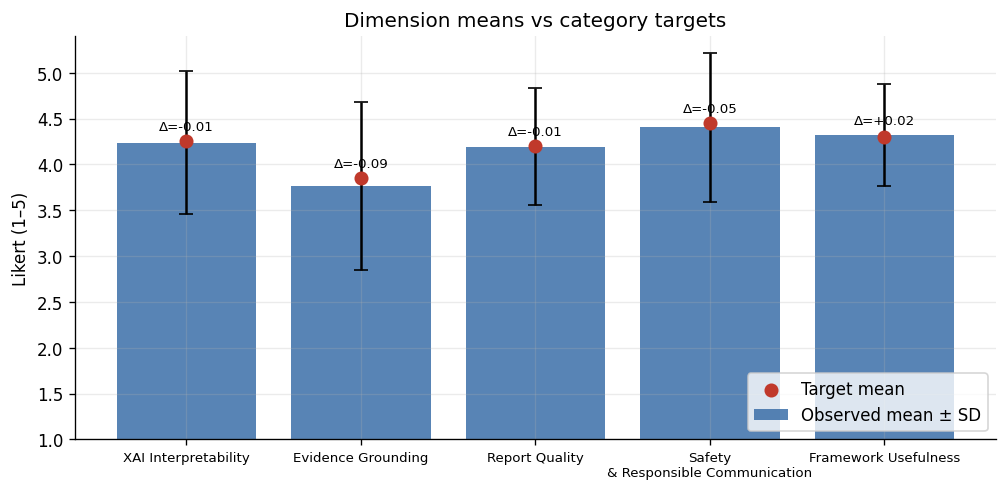

Interpretation notes:
- XAI Interpretability: 4.24 (target 4.25) → at/above target by -0.01
- Evidence Grounding: 3.76 (target 3.85) → below target by -0.09
- Report Quality: 4.19 (target 4.20) → at/above target by -0.01
- Safety & Responsible Communication: 4.40 (target 4.45) → at/above target by -0.05
- Framework Usefulness: 4.32 (target 4.30) → at/above target by +0.02


In [7]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
x = np.arange(len(DIMS))
means = dim_pooled["mean"].values
sds = dim_pooled["sd"].values
targets = dim_pooled["Target_Mean"].values

bars = ax.bar(x, means, yerr=sds, capsize=4, color="#3b6ea8", alpha=0.85, label="Observed mean ± SD")
ax.scatter(x, targets, color="#c0392b", zorder=3, s=55, label="Target mean")
for i, (m, t) in enumerate(zip(means, targets)):
    ax.annotate(f"Δ={m-t:+.2f}", (i, max(m, t) + 0.12), ha="center", fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels([d.replace(" & ", "\n& ") for d in DIMS.keys()], fontsize=8)
ax.set_ylim(1, 5.4)
ax.set_ylabel("Likert (1–5)")
ax.set_title("Dimension means vs category targets")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

print("Interpretation notes:")
for dim, row in dim_pooled.iterrows():
    status = "at/above" if row["Delta_vs_target"] >= -0.05 else "below"
    print(f"- {dim}: {row['mean']:.2f} (target {row['Target_Mean']:.2f}) → {status} target by {row['Delta_vs_target']:+.2f}")

## 5. Weak items & evidence-grounding focus

Evidence grounding (esp. sufficiency / traceability) is typically the hardest dimension for RAG-style systems.

,mean,sd,Text,rank_among_all20
Question,,,,
Q5,4.222222,0.646762,The retrieved evidence passages are relevant t...,8
Q6,4.166667,0.707107,The retrieved evidence provides useful context...,7
Q7,3.166667,0.923548,The retrieved evidence is sufficient to suppor...,1
Q8,3.500000,0.923548,The relationship between the generated report ...,3


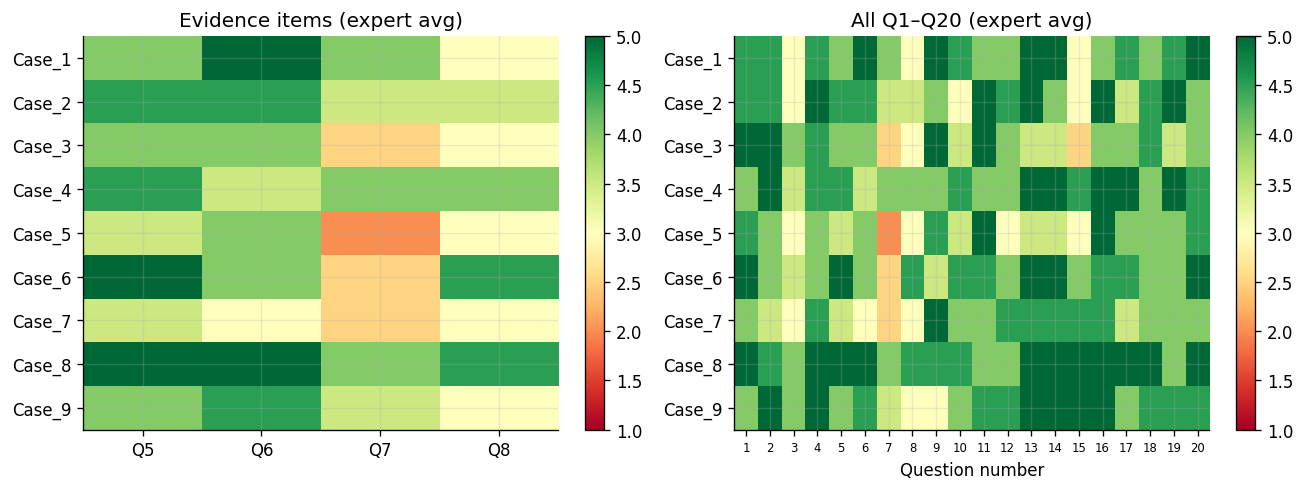

In [8]:
evidence_items = ["Q5", "Q6", "Q7", "Q8"]
ev = item_display.loc[evidence_items, ["mean", "sd", "Text"]].copy()
ev["rank_among_all20"] = item_display["mean"].rank(ascending=True).loc[evidence_items].astype(int)
display(ev)

# Case × evidence-item heatmap of expert-averaged scores
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

im0 = axes[0].imshow(avg_computed[evidence_items].values, cmap="RdYlGn", vmin=1, vmax=5, aspect="auto")
axes[0].set_xticks(range(4))
axes[0].set_xticklabels(evidence_items)
axes[0].set_yticks(range(len(avg_computed)))
axes[0].set_yticklabels(avg_computed.index)
axes[0].set_title("Evidence items (expert avg)")
plt.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(avg_computed[Q_COLS].values, cmap="RdYlGn", vmin=1, vmax=5, aspect="auto")
axes[1].set_xticks(range(20))
axes[1].set_xticklabels([q.replace("Q", "") for q in Q_COLS], fontsize=7)
axes[1].set_yticks(range(len(avg_computed)))
axes[1].set_yticklabels(avg_computed.index)
axes[1].set_xlabel("Question number")
axes[1].set_title("All Q1–Q20 (expert avg)")
plt.colorbar(im1, ax=axes[1], fraction=0.046)

plt.tight_layout()
plt.show()

## 6. Additional visualizations

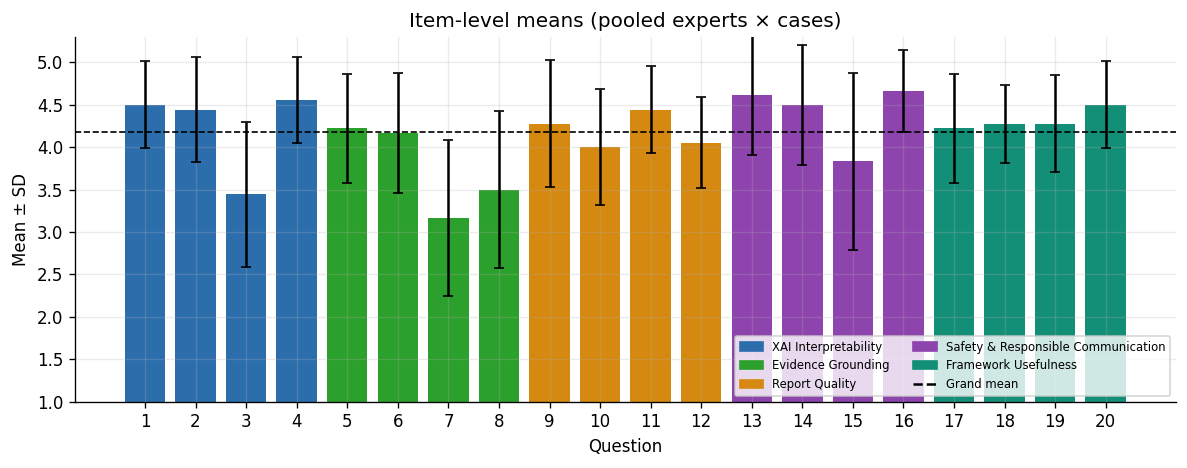

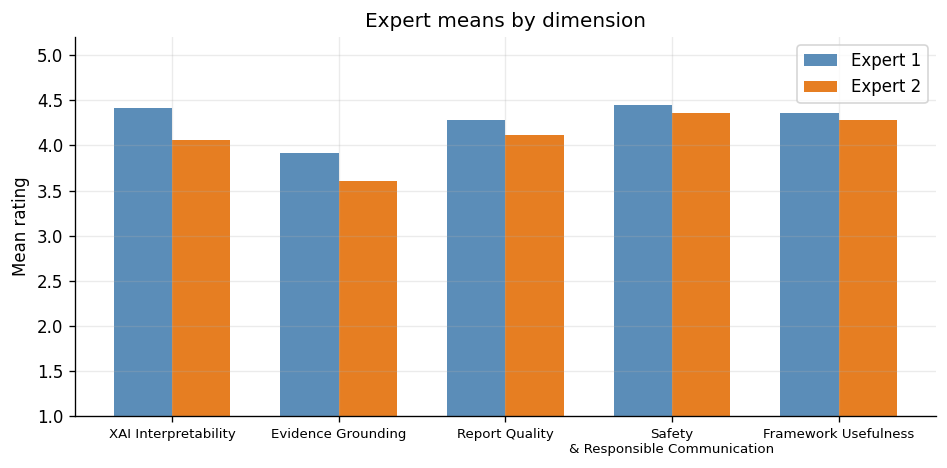

In [9]:
# Item means with SD error bars
fig, ax = plt.subplots(figsize=(10, 4))
means = item_stats["mean"].values
sds = item_stats["sd"].values
colors = {
    "XAI Interpretability": "#2c6eac",
    "Evidence Grounding": "#2ca02c",
    "Report Quality": "#d68910",
    "Safety & Responsible Communication": "#8e44ad",
    "Framework Usefulness": "#148f77",
}
bar_colors = [colors[q_to_dim[q]] for q in Q_COLS]
ax.bar(range(20), means, yerr=sds, capsize=3, color=bar_colors)
ax.axhline(long["Score"].mean(), color="black", ls="--", lw=1, label=f"Grand mean {long['Score'].mean():.2f}")
ax.set_xticks(range(20))
ax.set_xticklabels([q.replace("Q", "") for q in Q_COLS])
ax.set_xlabel("Question")
ax.set_ylabel("Mean ± SD")
ax.set_ylim(1, 5.3)
ax.set_title("Item-level means (pooled experts × cases)")
# legend proxies
from matplotlib.patches import Patch
handles = [Patch(color=c, label=d) for d, c in colors.items()]
handles.append(plt.Line2D([0], [0], color="black", ls="--", label="Grand mean"))
ax.legend(handles=handles, fontsize=7, loc="lower right", ncol=2)
plt.tight_layout()
plt.show()

# Expert comparison by dimension
fig, ax = plt.subplots(figsize=(8, 4))
dim_names = list(DIMS.keys())
x = np.arange(len(dim_names))
w = 0.35
e1_dim = [long.loc[(long.Expert == "E1") & (long.Dimension == d), "Score"].mean() for d in dim_names]
e2_dim = [long.loc[(long.Expert == "E2") & (long.Dimension == d), "Score"].mean() for d in dim_names]
ax.bar(x - w/2, e1_dim, w, label="Expert 1", color="#5b8db8")
ax.bar(x + w/2, e2_dim, w, label="Expert 2", color="#e67e22")
ax.set_xticks(x)
ax.set_xticklabels([d.replace(" & ", "\n& ") for d in dim_names], fontsize=8)
ax.set_ylim(1, 5.2)
ax.set_ylabel("Mean rating")
ax.set_title("Expert means by dimension")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Manuscript-ready summary tables

In [10]:
ms_dim = dim_pooled[["mean", "sd", "Target_Mean", "Delta_vs_target"]].copy()
ms_dim.columns = ["Mean", "SD", "Target", "Δ Target"]
ms_dim["Mean ± SD"] = ms_dim.apply(lambda r: f"{r['Mean']:.2f} ± {r['SD']:.2f}", axis=1)

ms_items = item_display[["Dimension", "mean", "sd", "Text"]].copy()
ms_items["Mean ± SD"] = ms_items.apply(lambda r: f"{r['mean']:.2f} ± {r['sd']:.2f}", axis=1)

print("=== Table A. Dimension summary (N_experts=2, N_cases=9, N_item_ratings=36 per dimension) ===")
display(ms_dim[["Mean ± SD", "Target", "Δ Target"]].round(3))

print("=== Table B. Item summary ===")
display(ms_items[["Dimension", "Mean ± SD", "Text"]])

print("=== Table C. Agreement ===")
display(agreement)

# Export tables for paper
out_dir = Path("expert_evaluation_analysis")
out_dir.mkdir(exist_ok=True)
ms_dim.to_csv(out_dir / "table_dimensions.csv")
ms_items.to_csv(out_dir / "table_items.csv")
agreement.to_csv(out_dir / "table_agreement.csv", index=False)
case_overall.round(3).to_csv(out_dir / "table_case_overall.csv")
avg_computed.round(2).to_csv(out_dir / "matrix_expert_avg_q1_q20.csv")
print("Wrote CSVs to", out_dir.resolve())

=== Table A. Dimension summary (N_experts=2, N_cases=9, N_item_ratings=36 per dimension) ===


,Mean ± SD,Target,Δ Target
Dimension,,,
XAI Interpretability,4.24 ± 0.78,4.25,-0.014
Evidence Grounding,3.76 ± 0.91,3.85,-0.086
Report Quality,4.19 ± 0.64,4.20,-0.006
Safety & Responsible Communication,4.40 ± 0.82,4.45,-0.047
Framework Usefulness,4.32 ± 0.55,4.30,0.019


=== Table B. Item summary ===


,Dimension,Mean ± SD,Text
Question,,,
Q1,XAI Interpretability,4.50 ± 0.51,The XAI explanation clearly identifies the mai...
Q2,XAI Interpretability,4.44 ± 0.62,The contribution of each feature is presented ...
Q3,XAI Interpretability,3.44 ± 0.86,The explanation appropriately distinguishes pr...
Q4,XAI Interpretability,4.56 ± 0.51,The XAI information improves understanding of ...
Q5,Evidence Grounding,4.22 ± 0.65,The retrieved evidence passages are relevant t...
Q6,Evidence Grounding,4.17 ± 0.71,The retrieved evidence provides useful context...
Q7,Evidence Grounding,3.17 ± 0.92,The retrieved evidence is sufficient to suppor...
Q8,Evidence Grounding,3.50 ± 0.92,The relationship between the generated report ...
Q9,Report Quality,4.28 ± 0.75,The generated report accurately reflects the m...


=== Table C. Agreement ===


,Metric,Value
0,Exact agreement,0.583333
1,Adjacent agreement (|Δ|≤1),0.950000
2,Mean |E1−E2|,0.466667
3,Pearson r (flattened),0.564444
4,Spearman ρ (flattened),0.563863
5,"ICC(2,1)",0.540887


Wrote CSVs to C:\Users\MossabBatal\Desktop\psychology_mas\paper_outputs\expert_evaluation_analysis


## 8. Narrative takeaways (for Results / Discussion)

Auto-generated from the loaded numbers — re-run after any data update.

In [11]:
best_dim = dim_pooled["mean"].idxmax()
worst_dim = dim_pooled["mean"].idxmin()
best_item = item_stats["mean"].idxmax()
worst_item = item_stats["mean"].idxmin()

print(f"""
KEY FINDINGS
============
Design: 2 experts × 9 cases × 20 Likert items (1–5) = {len(long)} ratings.

1. Overall favourability
   Grand mean = {long['Score'].mean():.2f} ± {long['Score'].std():.2f}.
   Strongest dimension: {best_dim} ({dim_pooled.loc[best_dim, 'mean']:.2f}).
   Weakest dimension: {worst_dim} ({dim_pooled.loc[worst_dim, 'mean']:.2f}).

2. Item extremes
   Highest: {best_item} = {item_stats.loc[best_item, 'mean']:.2f} — {questions.set_index('Question_ID').loc[best_item, 'Question_Text'][:90]}…
   Lowest:  {worst_item} = {item_stats.loc[worst_item, 'mean']:.2f} — {questions.set_index('Question_ID').loc[worst_item, 'Question_Text'][:90]}…

3. Agreement
   Exact agreement = {exact:.1%}; adjacent (|Δ|≤1) = {adjacent:.1%}; MAD = {mad:.2f}.
   ICC(2,1) = {icc21:.3f}; Pearson r = {pearson:.3f}.

4. Targets
   Observed vs category Target_Mean deltas:
{chr(10).join(f"   - {d}: {dim_pooled.loc[d, 'Delta_vs_target']:+.2f}" for d in DIMS)}

5. Practical implication
   Safety/communication and overall usefulness tend to rate highest; evidence sufficiency/
   traceability (Q7–Q8 region) is the main improvement lever for the RAG/report pipeline.
""")


KEY FINDINGS
Design: 2 experts × 9 cases × 20 Likert items (1–5) = 360 ratings.

1. Overall favourability
   Grand mean = 4.18 ± 0.78.
   Strongest dimension: Safety & Responsible Communication (4.40).
   Weakest dimension: Evidence Grounding (3.76).

2. Item extremes
   Highest: Q16 = 4.67 — The report appropriately indicates the need for professional follow-up when necessary.…
   Lowest:  Q7 = 3.17 — The retrieved evidence is sufficient to support the generated interpretation.…

3. Agreement
   Exact agreement = 58.3%; adjacent (|Δ|≤1) = 95.0%; MAD = 0.47.
   ICC(2,1) = 0.541; Pearson r = 0.564.

4. Targets
   Observed vs category Target_Mean deltas:
   - XAI Interpretability: -0.01
   - Evidence Grounding: -0.09
   - Report Quality: -0.01
   - Safety & Responsible Communication: -0.05
   - Framework Usefulness: +0.02

5. Practical implication
   Safety/communication and overall usefulness tend to rate highest; evidence sufficiency/
   traceability (Q7–Q8 region) is the main improve